# Breast Cancer Detection — Exploratory Data Analysis

**Project Domain:** Healthcare / Medical Machine Learning  
**Dataset:** Wisconsin Diagnostic Breast Cancer (WDBC)  
**Task:** Binary Classification  
**Target Variable:** `diagnosis`  
**Development Environment:** Python 3.10

---

## 1. Problem Definition

Breast cancer diagnosis is a binary classification problem in which
tumour characteristics are used to distinguish malignant from
benign cases.

The objective of this project is to develop a reproducible machine
learning pipeline using diagnostic measurements extracted from
digitised fine-needle aspiration (FNA) images.

The analysis will establish the statistical properties of the
dataset, identify relevant feature relationships, investigate
class distribution and assess data quality before model development.

## 2. Analytical Objectives

1. Establish dataset integrity and structural consistency.
2. Examine the distribution of diagnostic measurements.
3. Investigate differences between malignant and benign cases.
4. Identify feature relationships and potential multicollinearity.
5. Evaluate class distribution and its implications for model selection.
6. Establish evidence-based preprocessing and modelling decisions.

## 3. Dataset Description

The working dataset contains 569 observations, 30 numerical
predictor variables, a sample identifier and a binary diagnosis label.

The diagnostic measurements are organised into three groups:

- Mean measurements
- Standard error measurements
- Worst-case measurements

The target variable contains two classes:

- M: Malignant
- B: Benign

## 4. Analytical Principles

- Preserve the original raw dataset.
- Exclude identifiers from predictive modelling.
- Avoid data leakage during preprocessing and model selection.
- Fit transformations using training data only.
- Prioritise malignant-class recall alongside overall model performance.
- Record analytical findings and justify modelling decisions.


In [1]:

# ============================================================
# 1. ENVIRONMENT AND LIBRARY CONFIGURATION
# ============================================================

from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)

# Reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Display configuration
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")

# Visualisation configuration
sns.set_theme(
    style="whitegrid",
    context="notebook",
    palette="deep"
)

plt.rcParams.update({
    "figure.figsize": (10, 6),
    "figure.dpi": 120,
    "axes.titlesize": 14,
    "axes.labelsize": 11,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "figure.autolayout": True
})

print("Environment configured successfully.")
print(f"NumPy version: {np.__version__}")
print(f"Pandas version: {pd.__version__}")
print(f"Random state: {RANDOM_STATE}")


Environment configured successfully.
NumPy version: 2.2.6
Pandas version: 2.3.3
Random state: 42


In [2]:

# ============================================================
# 2. DATA INGESTION
# ============================================================

# Resolve project root independently of notebook launch location
ROOT = Path.cwd()

if not (ROOT / "data").exists():
    ROOT = ROOT.parent

DATA_PATH = ROOT / "data" / "processed" / "wdbc_cleaned.csv"

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Cleaned dataset not found: {DATA_PATH}"
    )

df = pd.read_csv(DATA_PATH)

print(f"Dataset loaded successfully: {DATA_PATH.name}")
print(f"Dataset dimensions: {df.shape[0]} rows × {df.shape[1]} columns")

display(df.head())


Dataset loaded successfully: wdbc_cleaned.csv
Dataset dimensions: 569 rows × 32 columns


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.9900,10.3800,122.8000,1001.0000,0.1184,0.2776,0.3001,0.1471,0.2419,0.0787,1.0950,0.9053,8.5890,153.4000,0.0064,0.0490,0.0537,0.0159,0.0300,0.0062,25.3800,17.3300,184.6000,2019.0000,0.1622,0.6656,0.7119,0.2654,0.4601,0.1189
1,842517,M,20.5700,17.7700,132.9000,1326.0000,0.0847,0.0786,0.0869,0.0702,0.1812,0.0567,0.5435,0.7339,3.3980,74.0800,0.0052,0.0131,0.0186,0.0134,0.0139,0.0035,24.9900,23.4100,158.8000,1956.0000,0.1238,0.1866,0.2416,0.1860,0.2750,0.0890
2,84300903,M,19.6900,21.2500,130.0000,1203.0000,0.1096,0.1599,0.1974,0.1279,0.2069,0.0600,0.7456,0.7869,4.5850,94.0300,0.0062,0.0401,0.0383,0.0206,0.0225,0.0046,23.5700,25.5300,152.5000,1709.0000,0.1444,0.4245,0.4504,0.2430,0.3613,0.0876
3,84348301,M,11.4200,20.3800,77.5800,386.1000,0.1425,0.2839,0.2414,0.1052,0.2597,0.0974,0.4956,1.1560,3.4450,27.2300,0.0091,0.0746,0.0566,0.0187,0.0596,0.0092,14.9100,26.5000,98.8700,567.7000,0.2098,0.8663,0.6869,0.2575,0.6638,0.1730
4,84358402,M,20.2900,14.3400,135.1000,1297.0000,0.1003,0.1328,0.1980,0.1043,0.1809,0.0588,0.7572,0.7813,5.4380,94.4400,0.0115,0.0246,0.0569,0.0188,0.0176,0.0051,22.5400,16.6700,152.2000,1575.0000,0.1374,0.2050,0.4000,0.1625,0.2364,0.0768


In [3]:

# ============================================================
# 3. DATASET INTEGRITY CHECK
# ============================================================

assert df.shape == (569, 32), "Unexpected dataset dimensions."

assert "id" in df.columns
assert "diagnosis" in df.columns

assert df["id"].is_unique, "Duplicate sample identifiers detected."

assert set(df["diagnosis"].unique()) == {"B", "M"}

assert df.isnull().sum().sum() == 0, "Missing values detected."

# Separate metadata, target and predictors
sample_ids = df["id"].copy()
y = df["diagnosis"].copy()

X = df.drop(columns=["id", "diagnosis"])

assert X.shape[1] == 30
assert all(pd.api.types.is_numeric_dtype(X[c]) for c in X.columns)

print("DATASET INTEGRITY: PASSED")
print(f"Observations: {len(df)}")
print(f"Predictor variables: {X.shape[1]}")
print(f"Target classes: {sorted(y.unique())}")
print(f"Missing values: {df.isnull().sum().sum()}")
print(f"Duplicate observations: {df.duplicated().sum()}")
print(f"Duplicate identifiers: {sample_ids.duplicated().sum()}")


DATASET INTEGRITY: PASSED
Observations: 569
Predictor variables: 30
Target classes: ['B', 'M']
Missing values: 0
Duplicate observations: 0
Duplicate identifiers: 0



## 5. Target Variable Distribution

The target variable `diagnosis` represents the diagnostic classification
of each observation.

This section examines the distribution of benign and malignant cases
to understand class representation and identify potential imbalance
that may influence model evaluation.


,Count,Percentage
diagnosis,,
Benign,357,62.7400
Malignant,212,37.2600


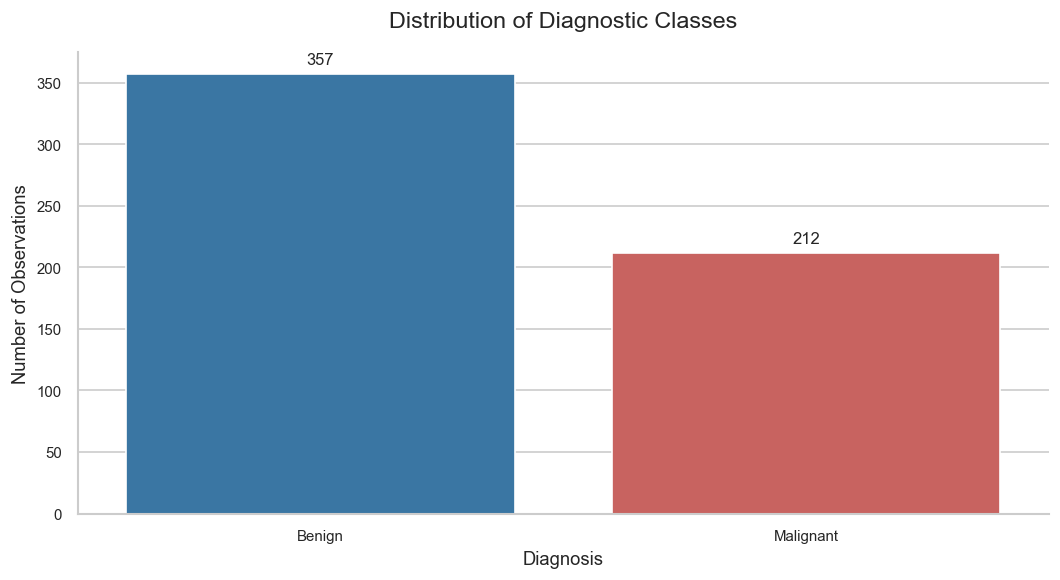

In [4]:

# ============================================================
# 5. TARGET DISTRIBUTION ANALYSIS
# ============================================================

class_counts = y.value_counts().sort_index()
class_percentages = y.value_counts(normalize=True).sort_index() * 100

class_summary = pd.DataFrame({
    "Count": class_counts,
    "Percentage": class_percentages
})

class_summary.index = class_summary.index.map({
    "B": "Benign",
    "M": "Malignant"
})

display(class_summary.round(2))

# Visualise class distribution
fig, ax = plt.subplots(figsize=(9, 5))

sns.barplot(
    x=class_summary.index,
    y=class_summary["Count"],
    hue=class_summary.index,
    palette=["#2878B5", "#D9534F"],
    legend=False,
    ax=ax
)

ax.set_title("Distribution of Diagnostic Classes", pad=15)
ax.set_xlabel("Diagnosis")
ax.set_ylabel("Number of Observations")

for container in ax.containers:
    ax.bar_label(container, padding=4, fontsize=10)

sns.despine()
plt.tight_layout()
plt.show()


,Count,Percentage
diagnosis,,
Benign,357,62.7400
Malignant,212,37.2600


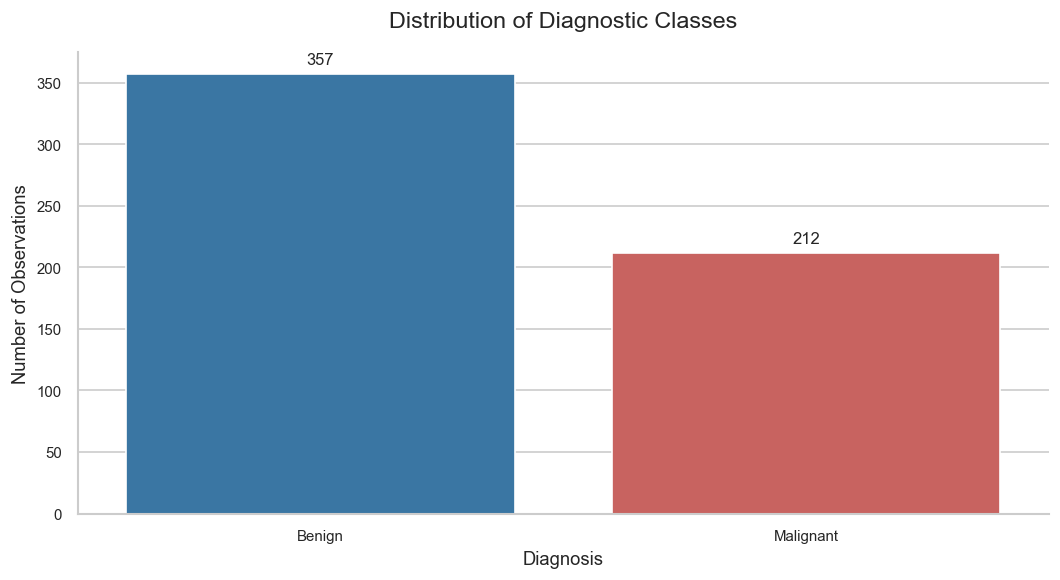

In [5]:

# ============================================================
# 5. TARGET DISTRIBUTION ANALYSIS
# ============================================================

class_counts = y.value_counts().sort_index()
class_percentages = y.value_counts(normalize=True).sort_index() * 100

class_summary = pd.DataFrame({
    "Count": class_counts,
    "Percentage": class_percentages
})

class_summary.index = class_summary.index.map({
    "B": "Benign",
    "M": "Malignant"
})

display(class_summary.round(2))

# Visualise class distribution
fig, ax = plt.subplots(figsize=(9, 5))

sns.barplot(
    x=class_summary.index,
    y=class_summary["Count"],
    hue=class_summary.index,
    palette=["#2878B5", "#D9534F"],
    legend=False,
    ax=ax
)

ax.set_title("Distribution of Diagnostic Classes", pad=15)
ax.set_xlabel("Diagnosis")
ax.set_ylabel("Number of Observations")

for container in ax.containers:
    ax.bar_label(container, padding=4, fontsize=10)

sns.despine()
plt.tight_layout()
plt.show()



## 6. Descriptive Statistical Analysis

Descriptive statistics provide an initial understanding of the
distribution, central tendency and variability of the diagnostic
predictors.

The analysis includes measures of:
- Mean and standard deviation
- Minimum and maximum values
- First and third quartiles
- Median values


In [7]:

# ============================================================
# 6. DESCRIPTIVE STATISTICAL PROFILE
# ============================================================

descriptive_stats = X.describe().T

descriptive_stats["median"] = X.median()

descriptive_stats["coefficient_of_variation"] = (
    X.std() / X.mean().abs()
)

display(
    descriptive_stats.round(4)
)


,count,mean,std,min,25%,50%,75%,max,median,coefficient_of_variation
radius_mean,569.0000,14.1273,3.5240,6.9810,11.7000,13.3700,15.7800,28.1100,13.3700,0.2494
texture_mean,569.0000,19.2896,4.3010,9.7100,16.1700,18.8400,21.8000,39.2800,18.8400,0.2230
perimeter_mean,569.0000,91.9690,24.2990,43.7900,75.1700,86.2400,104.1000,188.5000,86.2400,0.2642
area_mean,569.0000,654.8891,351.9141,143.5000,420.3000,551.1000,782.7000,2501.0000,551.1000,0.5374
smoothness_mean,569.0000,0.0964,0.0141,0.0526,0.0864,0.0959,0.1053,0.1634,0.0959,0.1460
compactness_mean,569.0000,0.1043,0.0528,0.0194,0.0649,0.0926,0.1304,0.3454,0.0926,0.5062
concavity_mean,569.0000,0.0888,0.0797,0.0000,0.0296,0.0615,0.1307,0.4268,0.0615,0.8978
concave points_mean,569.0000,0.0489,0.0388,0.0000,0.0203,0.0335,0.0740,0.2012,0.0335,0.7932
symmetry_mean,569.0000,0.1812,0.0274,0.1060,0.1619,0.1792,0.1957,0.3040,0.1792,0.1513
fractal_dimension_mean,569.0000,0.0628,0.0071,0.0500,0.0577,0.0615,0.0661,0.0974,0.0615,0.1124



## 7. Comparative Feature Analysis by Diagnosis

This section investigates differences in diagnostic measurements
between benign and malignant observations.

Class-wise descriptive statistics and distribution plots are used
to examine differences in central tendency, variability and
overlapping feature distributions.

The analysis focuses on selected morphological characteristics,
including radius, perimeter, area, concavity and concave points.

These comparisons are exploratory and do not establish clinical
causality or independent predictive importance.


In [8]:

# ============================================================
# 7.1 CLASS-WISE DESCRIPTIVE ANALYSIS
# ============================================================

selected_features = [
    "radius_mean",
    "texture_mean",
    "perimeter_mean",
    "area_mean",
    "concavity_mean",
    "concave points_mean"
]

class_comparison = (
    df.groupby("diagnosis")[selected_features]
      .agg(["mean", "median", "std"])
      .round(4)
)

display(class_comparison)


radius_mean                texture_mean                 \
                 mean  median    std         mean  median    std   
diagnosis                                                          
B             12.1465 12.2000 1.7805      17.9148 17.3900 3.9951   
M             17.4628 17.3250 3.2040      21.6049 21.4600 3.7795   

          perimeter_mean                  area_mean                    \
                    mean   median     std      mean   median      std   
diagnosis                                                               
B                78.0754  78.1800 11.8074  462.7902 458.4000 134.2871   
M               115.3654 114.2000 21.8547  978.3764 932.0000 367.9380   

          concavity_mean               concave points_mean                
                    mean median    std                mean median    std  
diagnosis                                                                 
B                 0.0461 0.0371 0.0434              0.0257 0.0234 0.0159  
M                 0.1608 0.1513 0.0750              0.0880 0.0863 0.0344

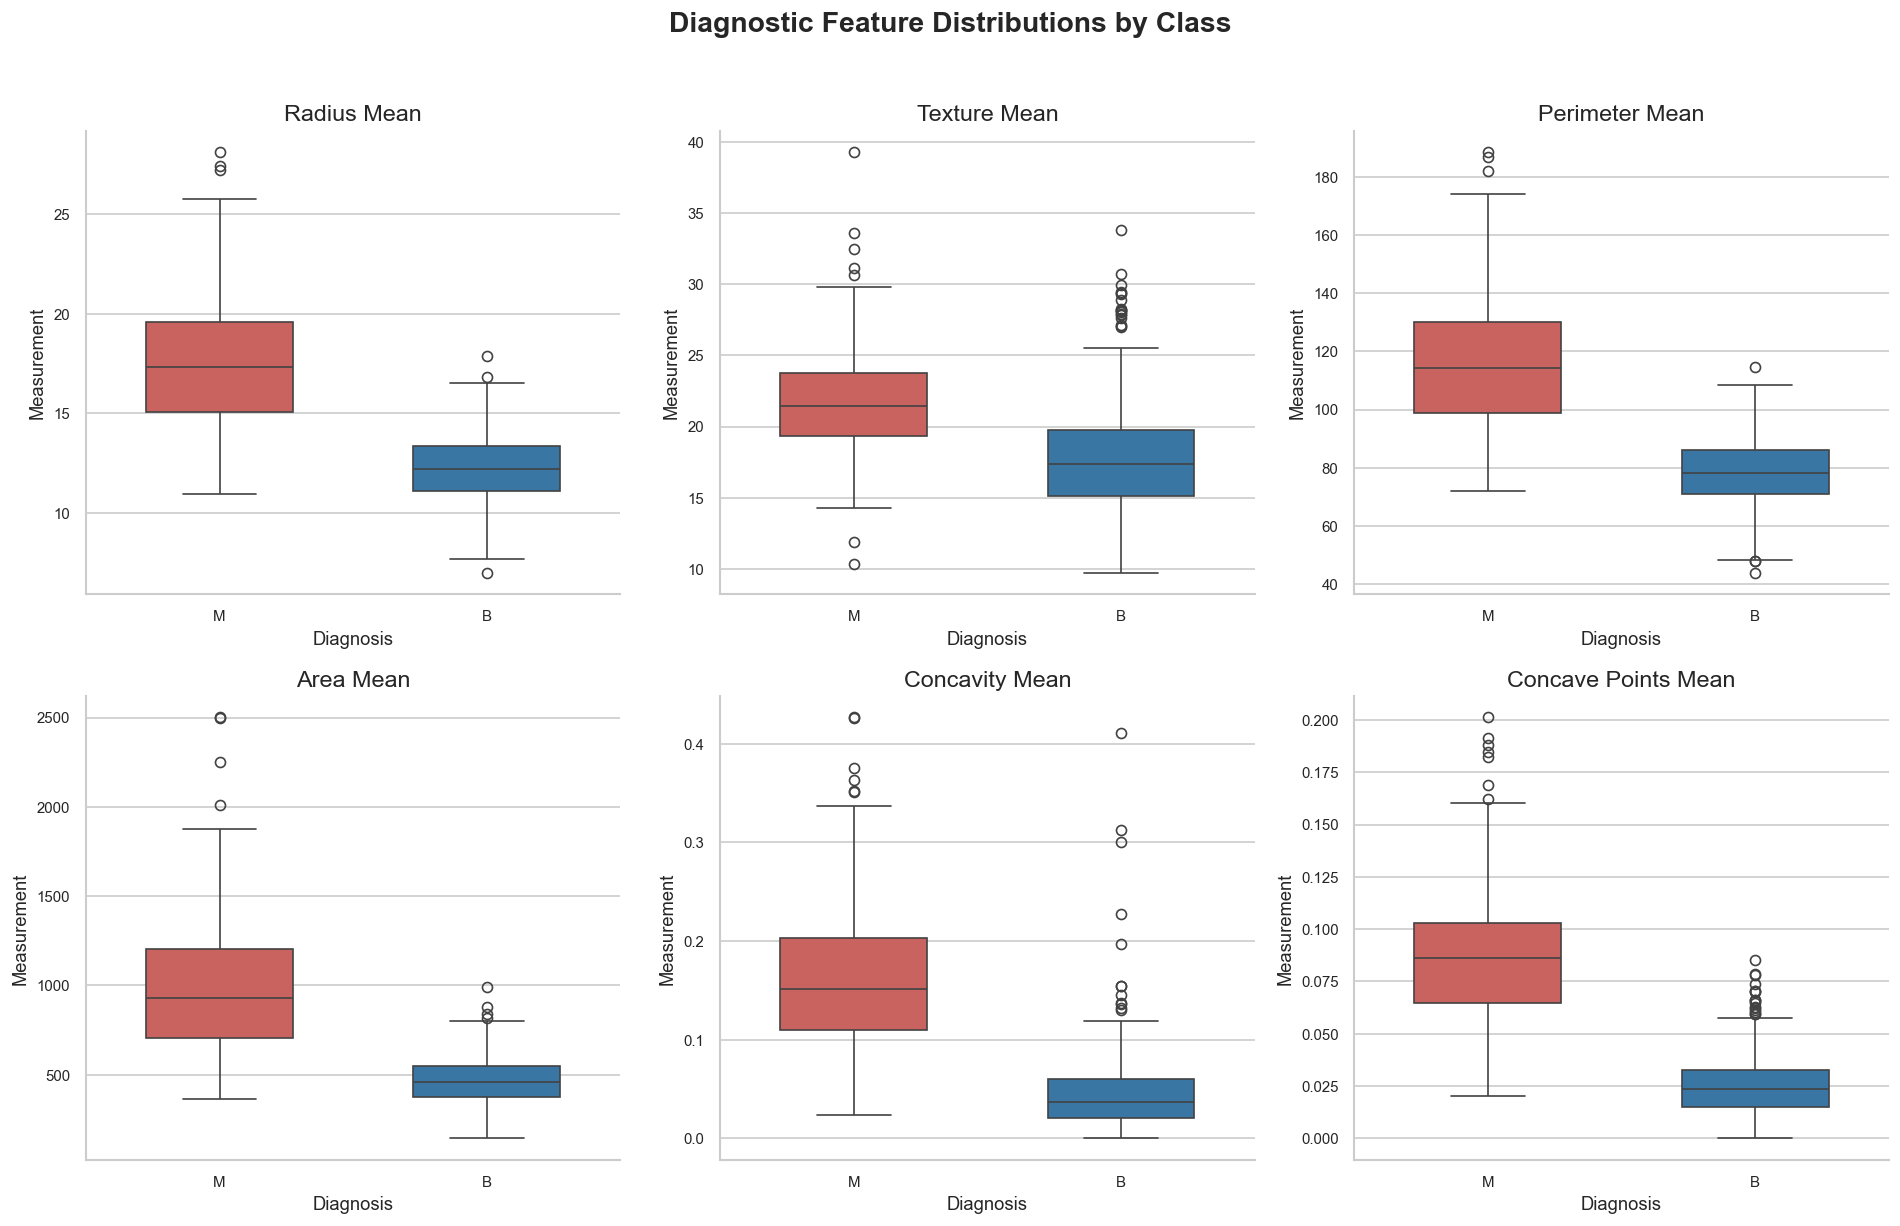

In [9]:

# ============================================================
# 7.2 FEATURE DISTRIBUTION BY DIAGNOSIS
# ============================================================

fig, axes = plt.subplots(2, 3, figsize=(16, 10))

for ax, feature in zip(axes.flat, selected_features):

    sns.boxplot(
        data=df,
        x="diagnosis",
        y=feature,
        hue="diagnosis",
        palette={"B": "#2878B5", "M": "#D9534F"},
        legend=False,
        showfliers=True,
        width=0.55,
        ax=ax
    )

    ax.set_title(feature.replace("_", " ").title())
    ax.set_xlabel("Diagnosis")
    ax.set_ylabel("Measurement")

fig.suptitle(
    "Diagnostic Feature Distributions by Class",
    fontsize=17,
    fontweight="bold",
    y=1.02
)

sns.despine()
plt.tight_layout()
plt.show()


In [10]:

# ============================================================
# 7.3 RELATIVE DIFFERENCE IN CLASS MEANS
# ============================================================

class_means = df.groupby("diagnosis")[selected_features].mean()

comparison = pd.DataFrame({
    "Benign Mean": class_means.loc["B"],
    "Malignant Mean": class_means.loc["M"]
})

comparison["Absolute Difference"] = (
    comparison["Malignant Mean"] - comparison["Benign Mean"]
)

comparison["Relative Difference (%)"] = (
    comparison["Absolute Difference"]
    / comparison["Benign Mean"].abs()
) * 100

display(comparison.round(3))


,Benign Mean,Malignant Mean,Absolute Difference,Relative Difference (%)
radius_mean,12.1470,17.4630,5.3160,43.7680
texture_mean,17.9150,21.6050,3.6900,20.5980
perimeter_mean,78.0750,115.3650,37.2900,47.7610
area_mean,462.7900,978.3760,515.5860,111.4080
concavity_mean,0.0460,0.1610,0.1150,249.0730
concave points_mean,0.0260,0.0880,0.0620,242.1420



## 8. Correlation and Multicollinearity Analysis

This section examines relationships among numerical diagnostic
predictors using Spearman rank correlation.

The objective is to:

- Identify strongly associated predictor variables.
- Investigate potential multicollinearity.
- Examine monotonic relationships between diagnostic features.
- Identify redundant measurements that may affect model interpretation.

Correlation does not establish causation or independent predictive importance.


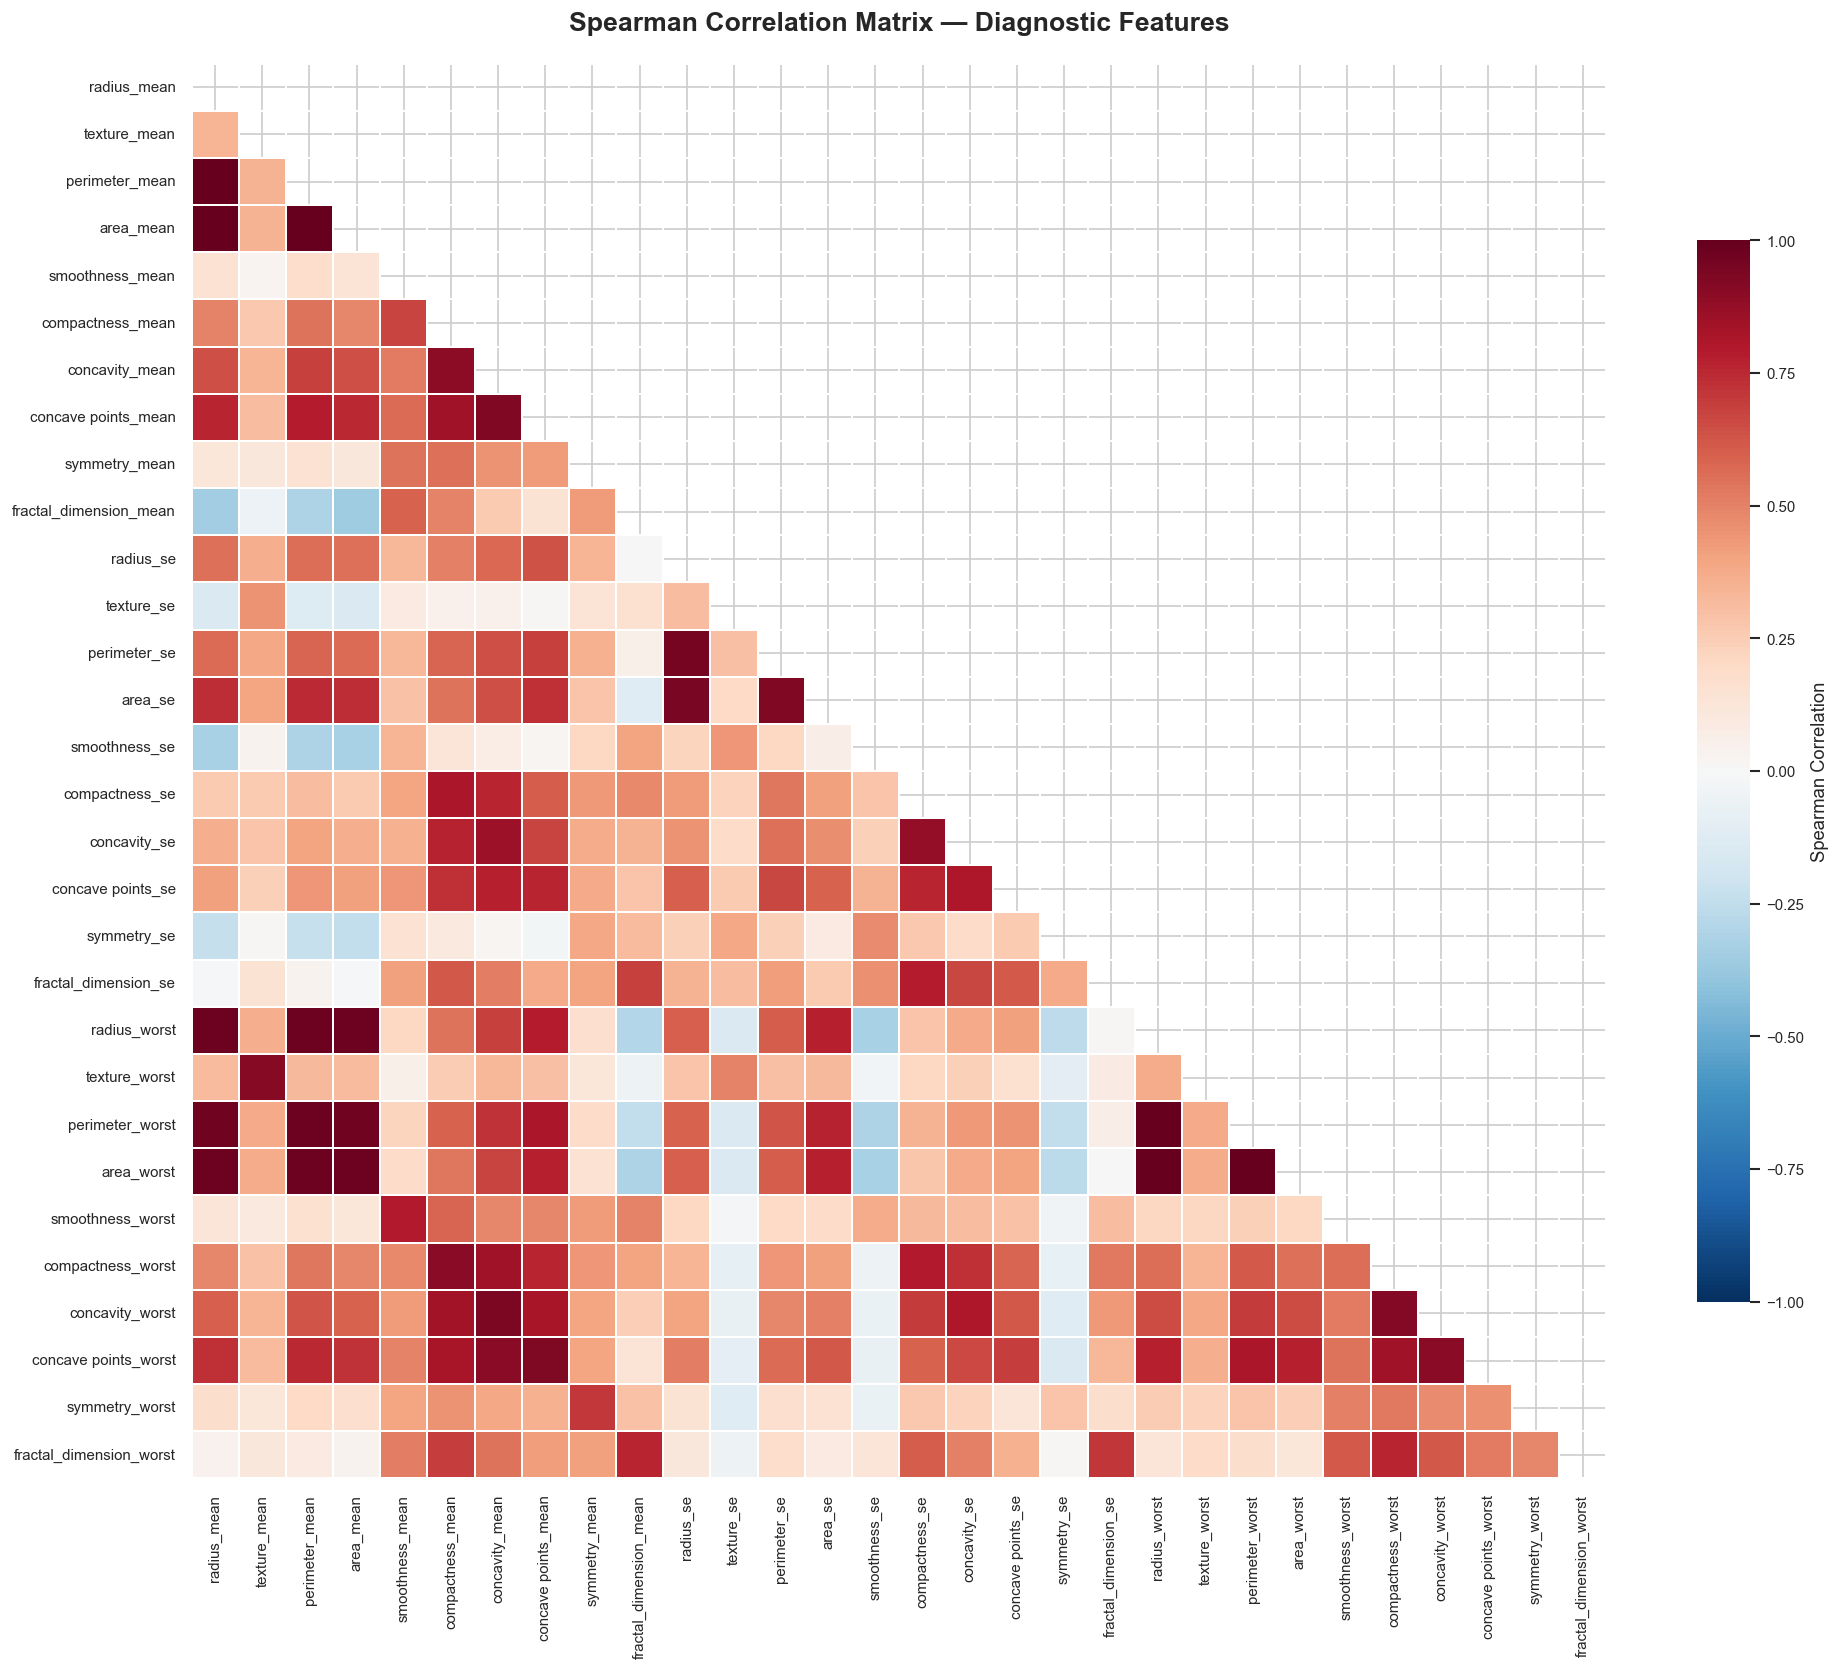

In [11]:

# ============================================================
# 8.1 SPEARMAN CORRELATION ANALYSIS
# ============================================================

correlation_matrix = X.corr(method="spearman")

mask = np.triu(
    np.ones_like(correlation_matrix, dtype=bool)
)

fig, ax = plt.subplots(figsize=(17, 14))

sns.heatmap(
    correlation_matrix,
    mask=mask,
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.25,
    cbar_kws={
        "shrink": 0.75,
        "label": "Spearman Correlation"
    },
    ax=ax
)

ax.set_title(
    "Spearman Correlation Matrix — Diagnostic Features",
    fontsize=16,
    fontweight="bold",
    pad=20
)

plt.tight_layout()
plt.show()


In [12]:

# ============================================================
# 8.2 HIGH-CORRELATION FEATURE PAIRS
# ============================================================

upper_triangle = correlation_matrix.where(
    np.triu(
        np.ones(correlation_matrix.shape),
        k=1
    ).astype(bool)
)

high_correlation_pairs = (
    upper_triangle
    .stack()
    .reset_index()
)

high_correlation_pairs.columns = [
    "Feature 1",
    "Feature 2",
    "Spearman Correlation"
]

high_correlation_pairs["Absolute Correlation"] = (
    high_correlation_pairs["Spearman Correlation"].abs()
)

high_correlation_pairs = (
    high_correlation_pairs[
        high_correlation_pairs["Absolute Correlation"] >= 0.90
    ]
    .sort_values(
        "Absolute Correlation",
        ascending=False
    )
    .reset_index(drop=True)
)

print("Highly correlated feature pairs (|rho| >= 0.90):")

display(high_correlation_pairs.round(4))


Highly correlated feature pairs (|rho| >= 0.90):


,Feature 1,Feature 2,Spearman Correlation,Absolute Correlation
0,radius_mean,area_mean,0.9996,0.9996
1,radius_worst,area_worst,0.9989,0.9989
2,radius_mean,perimeter_mean,0.9978,0.9978
3,perimeter_mean,area_mean,0.9971,0.9971
4,radius_worst,perimeter_worst,0.9935,0.9935
5,perimeter_worst,area_worst,0.9924,0.9924
6,perimeter_mean,radius_worst,0.9812,0.9812
7,perimeter_mean,area_worst,0.9809,0.9809
8,area_mean,area_worst,0.9803,0.9803
9,area_mean,radius_worst,0.9793,0.9793


In [13]:

# ============================================================
# 8.3 FEATURE-DIAGNOSIS ASSOCIATION
# ============================================================

diagnosis_encoded = y.map({
    "B": 0,
    "M": 1
})

target_association = (
    X.corrwith(diagnosis_encoded, method="spearman")
    .sort_values(key=abs, ascending=False)
    .rename("Spearman Correlation")
    .to_frame()
)

display(target_association.round(4).head(15))


,Spearman Correlation
perimeter_worst,0.7963
radius_worst,0.7879
area_worst,0.7869
concave points_worst,0.7817
concave points_mean,0.7779
perimeter_mean,0.7485
area_mean,0.7341
concavity_mean,0.7333
radius_mean,0.7328
area_se,0.7142



## 9. Feature Association with Diagnostic Outcome

Spearman correlation is used to rank predictor variables according
to their monotonic association with the binary diagnostic outcome.

This analysis provides an exploratory ranking of candidate features
for subsequent modelling and explainability.


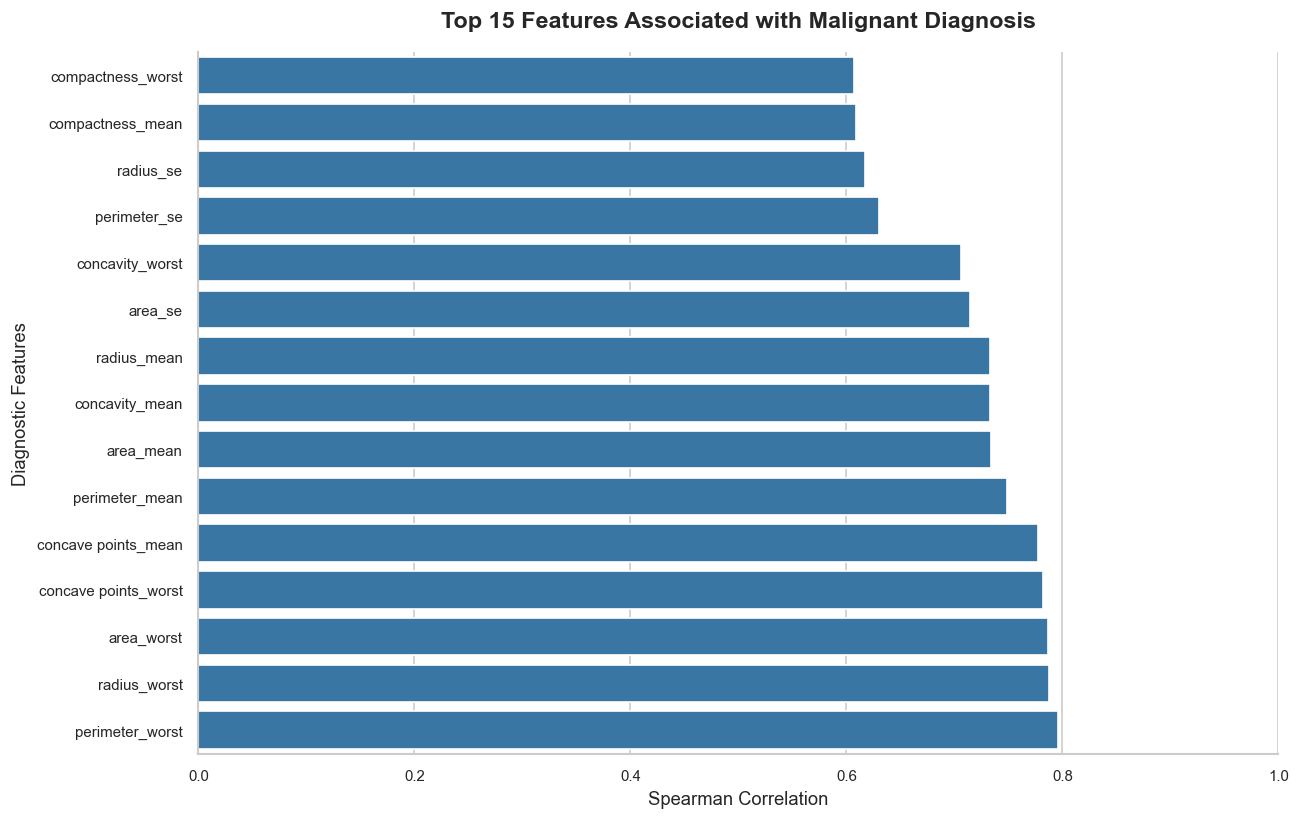

In [14]:

# ============================================================
# 9. FEATURE-DIAGNOSIS ASSOCIATION VISUALISATION
# ============================================================

top_features = target_association.head(15).sort_values(
    "Spearman Correlation"
)

fig, ax = plt.subplots(figsize=(11, 7))

sns.barplot(
    x="Spearman Correlation",
    y=top_features.index,
    data=top_features,
    color="#2878B5",
    ax=ax
)

ax.set_title(
    "Top 15 Features Associated with Malignant Diagnosis",
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Spearman Correlation")
ax.set_ylabel("Diagnostic Features")
ax.set_xlim(0, 1)

sns.despine()
plt.tight_layout()
plt.show()



## 10. Outlier Detection and Investigation

The Interquartile Range (IQR) method is applied to identify
potentially extreme observations within the diagnostic predictors.

For each feature:

IQR = Q3 - Q1

Lower Bound = Q1 - 1.5 × IQR

Upper Bound = Q3 + 1.5 × IQR

Observations outside these boundaries are flagged for investigation.

Outlier identification is performed for exploratory purposes.
No observations are removed at this stage.


In [15]:

# ============================================================
# 10.1 IQR-BASED OUTLIER DETECTION
# ============================================================

Q1 = X.quantile(0.25)
Q3 = X.quantile(0.75)

IQR = Q3 - Q1

lower_bounds = Q1 - 1.5 * IQR
upper_bounds = Q3 + 1.5 * IQR

outlier_mask = (
    (X.lt(lower_bounds)) |
    (X.gt(upper_bounds))
)

outlier_summary = pd.DataFrame({
    "Outlier Count": outlier_mask.sum(),
    "Outlier Percentage": (
        outlier_mask.mean() * 100
    ),
    "Lower Bound": lower_bounds,
    "Upper Bound": upper_bounds
})

outlier_summary = outlier_summary.sort_values(
    "Outlier Count",
    ascending=False
)

display(outlier_summary.round(3))


,Outlier Count,Outlier Percentage,Lower Bound,Upper Bound
area_se,65,11.4240,-23.1600,86.2000
radius_se,38,6.6780,-0.1370,0.8490
perimeter_se,38,6.6780,-1.0200,5.9840
area_worst,35,6.1510,-337.7500,1937.0500
smoothness_se,30,5.2720,0.0010,0.0130
fractal_dimension_se,28,4.9210,-0.0010,0.0080
compactness_se,28,4.9210,-0.0160,0.0620
symmetry_se,27,4.7450,0.0030,0.0360
area_mean,25,4.3940,-123.3000,1326.3000
fractal_dimension_worst,24,4.2180,0.0410,0.1230


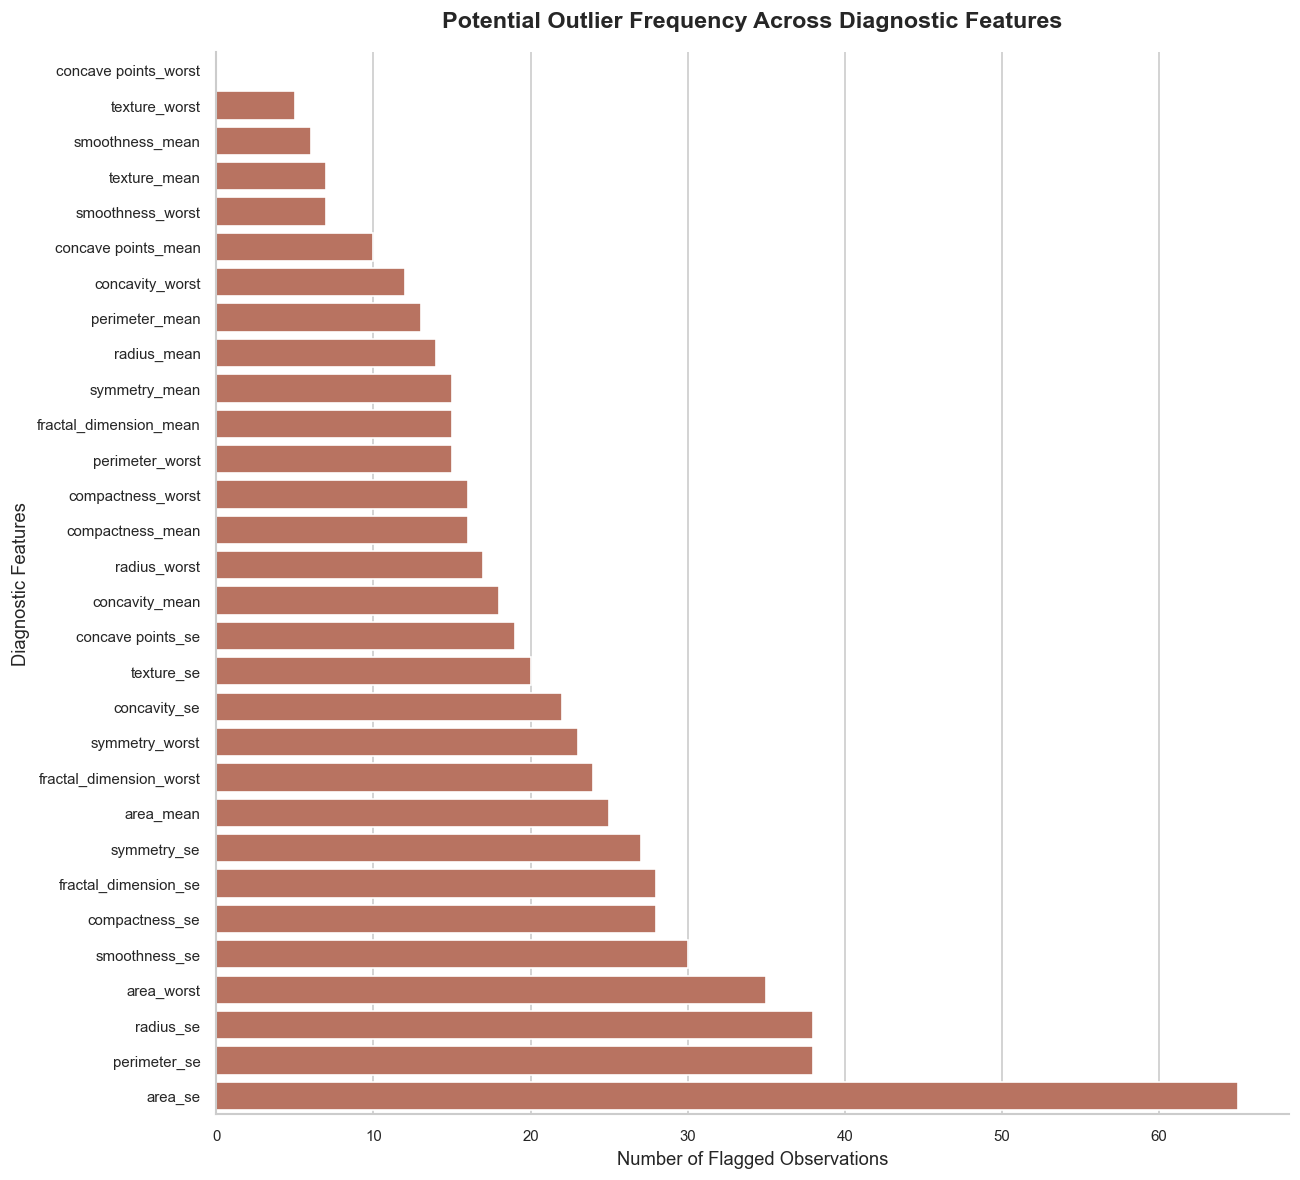

In [16]:

# ============================================================
# 10.2 OUTLIER FREQUENCY VISUALISATION
# ============================================================

outlier_plot = outlier_summary.sort_values(
    "Outlier Count",
    ascending=True
)

fig, ax = plt.subplots(figsize=(11, 10))

sns.barplot(
    data=outlier_plot,
    x="Outlier Count",
    y=outlier_plot.index,
    color="#C76B52",
    ax=ax
)

ax.set_title(
    "Potential Outlier Frequency Across Diagnostic Features",
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Number of Flagged Observations")
ax.set_ylabel("Diagnostic Features")

sns.despine()
plt.tight_layout()
plt.show()


In [17]:

# ============================================================
# EDA VISUALIZATION EXPORT CONFIGURATION
# ============================================================

EDA_OUTPUT_DIR = ROOT / "outputs" / "eda"

EDA_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("EDA output directory:", EDA_OUTPUT_DIR)
print("Visualization export directory ready.")


EDA output directory: c:\Users\nidhi\Breast-Cancer-Detection-ML\outputs\eda
Visualization export directory ready.


In [18]:
fig.savefig(
    EDA_OUTPUT_DIR / "class_distribution.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

In [19]:
fig.savefig(
    EDA_OUTPUT_DIR / "feature_comparison.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

In [20]:
fig.savefig(
    EDA_OUTPUT_DIR / "correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

In [21]:
fig.savefig(
    EDA_OUTPUT_DIR / "feature_association.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

In [22]:
fig.savefig(
    EDA_OUTPUT_DIR / "outlier_analysis.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)